# 📊 Insurance Charges Analysis

### Project Overview

Este proyecto analiza 1.338 registros de asegurados en EE.UU. para entender que variables (edad, bmi, hijos, fumador) explican mejor el gasto medico anual (charges), y para construir un modelo de regresion lineal simple y multiple que responda una pregunta de negocio real:

> Que variables predicen mejor el gasto medico anual, y como deberia una aseguradora ajustar sus primas segun el perfil de riesgo del asegurado?

## 🔍 Primeros pasos

### 1- Importar librerias necesarias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


### 2- Cargar el archivo CSV

In [2]:
file_path = "../data/raw/insurance.csv"
df = pd.read_csv(file_path)


### 3- Visualizar primeras filas del dataset

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### 4- Tipos de datos y estructura

In [4]:
df.info()
print(f"Numero de filas: {df.shape[0]}")
print(f"Numero de columnas: {df.shape[1]}")


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
Numero de filas: 1338
Numero de columnas: 7


### 5- Describir variables numericas y categoricas

In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### 6- Valores nulos y duplicados

In [6]:
print(df.isnull().sum())
print("Duplicados:", df.duplicated().sum())


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicados: 1


📌 El dataset no presenta valores nulos ni filas duplicadas, por lo que no es necesario aplicar imputacion ni eliminar registros antes de continuar con el analisis.

## 📈 Estadistica descriptiva de charges

### 7- Media, mediana, dispersion y forma de la distribucion

In [7]:
mean_charges = df['charges'].mean()
median_charges = df['charges'].median()
std_charges = df['charges'].std()
cv_charges = (std_charges / mean_charges) * 100
skew_charges = stats.skew(df['charges'])
kurt_charges = stats.kurtosis(df['charges'])

print(f"Media: {mean_charges:.2f}")
print(f"Mediana: {median_charges:.2f}")
print(f"Desviacion estandar: {std_charges:.2f}")
print(f"Coeficiente de variacion: {cv_charges:.2f}%")
print(f"Skewness: {skew_charges:.2f}")
print(f"Kurtosis (exceso): {kurt_charges:.2f}")


Media: 13270.42
Mediana: 9382.03
Desviacion estandar: 12110.01
Coeficiente de variacion: 91.26%
Skewness: 1.51
Kurtosis (exceso): 1.60


📌 La media (13.270) es un 42% mayor que la mediana (9.382), y el skewness de 1.51 confirma una distribucion muy sesgada a la derecha. La mediana es la medida de tendencia central mas representativa del asegurado tipico.

### 8- Histograma de charges

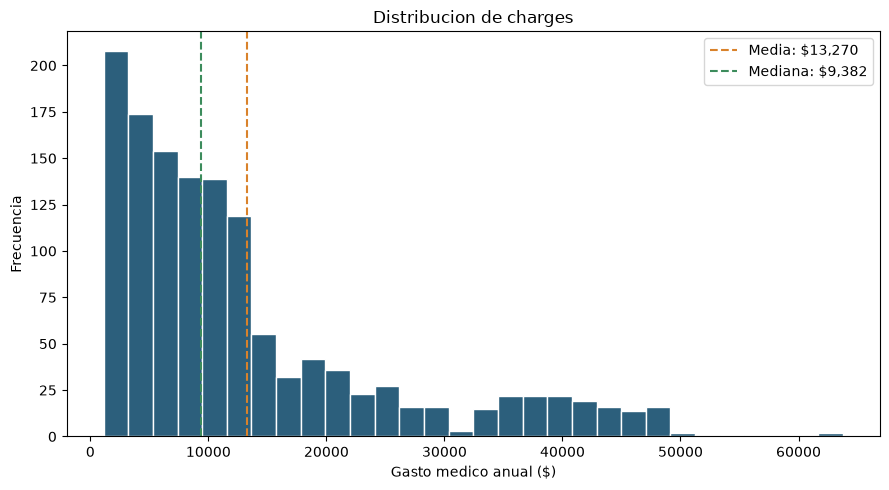

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df['charges'], bins=30, color='#2C5F7C', edgecolor='white')
ax.axvline(mean_charges, color='#D9822B', linestyle='--', label=f'Media: ${mean_charges:,.0f}')
ax.axvline(median_charges, color='#3C8C5C', linestyle='--', label=f'Mediana: ${median_charges:,.0f}')
ax.set_xlabel('Gasto medico anual ($)')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribucion de charges')
ax.legend()
plt.tight_layout()
plt.show()


### 9- charges segmentado por condicion de fumador

In [9]:
smoker_summary = df.groupby('smoker')['charges'].agg(['mean', 'median', 'std', 'count'])
smoker_summary


,mean,median,std,count
smoker,,,,
no,8434.268298,7345.40530,5993.781819,1064
yes,32050.231832,34456.34845,11541.547176,274


📌 Los fumadores gastan en promedio 3.8 veces mas que los no fumadores ($32.050 vs $8.434), lo que sugiere que `smoker` sera una variable clave en el modelo.

## Deteccion de outliers

### 10- Metodo IQR

In [10]:
Q1 = df['charges'].quantile(0.25)
Q3 = df['charges'].quantile(0.75)
IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

mask_iqr = (df['charges'] < lim_inf) | (df['charges'] > lim_sup)
print(f"Limite superior: {lim_sup:.2f}")
print(f"Outliers IQR: {mask_iqr.sum()} ({mask_iqr.mean()*100:.1f}%)")


Limite superior: 34489.35
Outliers IQR: 139 (10.4%)


### 11- Metodo Z-score

In [11]:
z_scores = (df['charges'] - mean_charges) / std_charges
mask_z = np.abs(z_scores) > 3
print(f"Outliers Z-score: {mask_z.sum()}")


Outliers Z-score: 7


### 12- Boxplot por fumador y perfil de los outliers

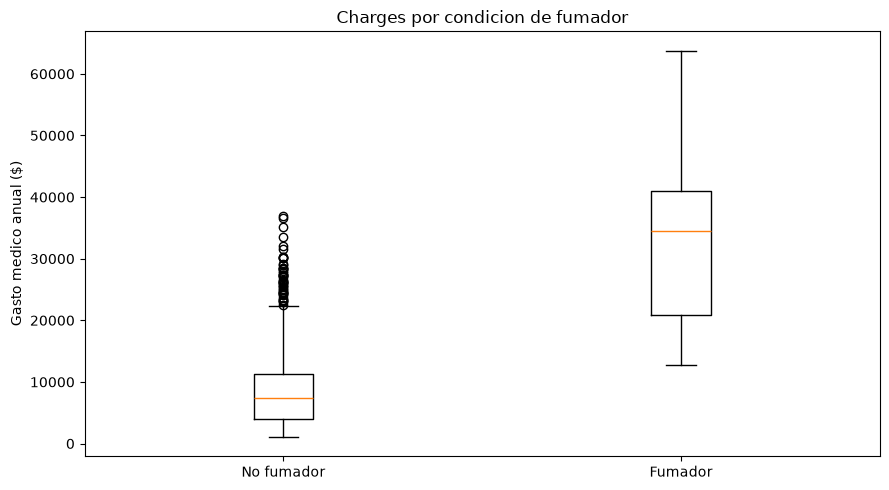

% fumadores entre los outliers IQR: 97.8%


In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
data = [df[df['smoker'] == 'no']['charges'], df[df['smoker'] == 'yes']['charges']]
ax.boxplot(data, tick_labels=['No fumador', 'Fumador'])
ax.set_ylabel('Gasto medico anual ($)')
ax.set_title('Charges por condicion de fumador')
plt.tight_layout()
plt.show()

pct_smokers = (df.loc[mask_iqr, 'smoker'] == 'yes').mean() * 100
print(f"% fumadores entre los outliers IQR: {pct_smokers:.1f}%")


📌 El 97.8% de los outliers detectados por IQR son fumadores: no son errores de datos, sino un segmento de riesgo legitimo que debe mantenerse e incorporarse al modelo, no eliminarse.

## 📉 Regresion lineal simple: charges ~ bmi

### 13- Ajuste del modelo

In [13]:
X_simple = df[['bmi']]
y = df['charges']

model_simple = LinearRegression()
model_simple.fit(X_simple, y)
pred_simple = model_simple.predict(X_simple)
r2_simple = r2_score(y, pred_simple)

print(f"Intercepto: {model_simple.intercept_:.2f}")
print(f"Coeficiente bmi: {model_simple.coef_[0]:.2f}")
print(f"R2: {r2_simple:.4f}")


Intercepto: 1192.94
Coeficiente bmi: 393.87
R2: 0.0393


📌 Con R2 = 0.039, el BMI por si solo explica menos del 4% de la variacion de charges. El scatter plot (bmi vs charges) muestra dos nubes de puntos separadas por condicion de fumador, evidenciando que falta una variable clave en el modelo.

## Regresion lineal multiple

### 14- Variables dummy y ajuste del modelo

In [14]:
df['smoker_yes'] = (df['smoker'] == 'yes').astype(int)

features = ['age', 'bmi', 'children', 'smoker_yes']
X_multi = df[features]

model_multi = LinearRegression()
model_multi.fit(X_multi, y)
pred_multi = model_multi.predict(X_multi)
residuals_multi = y - pred_multi
r2_multi = r2_score(y, pred_multi)

print(f"Intercepto: {model_multi.intercept_:.2f}")
for f, c in zip(features, model_multi.coef_):
    print(f"  {f}: {c:.2f}")
print(f"R2: {r2_multi:.4f}")


Intercepto: -12102.77
  age: 257.85
  bmi: 321.85
  children: 473.50
  smoker_yes: 23811.40
R2: 0.7497


### 15- Multicolinealidad entre predictores

In [15]:
df[['age', 'bmi', 'children']].corr()


,age,bmi,children
age,1.000000,0.109272,0.042469
bmi,0.109272,1.000000,0.012759
children,0.042469,0.012759,1.000000


📌 Todas las correlaciones entre predictores numericos son menores a 0.11: no hay problema de multicolinealidad y los coeficientes se pueden interpretar de forma independiente (ceteris paribus).

### 16- Grafico de residuos

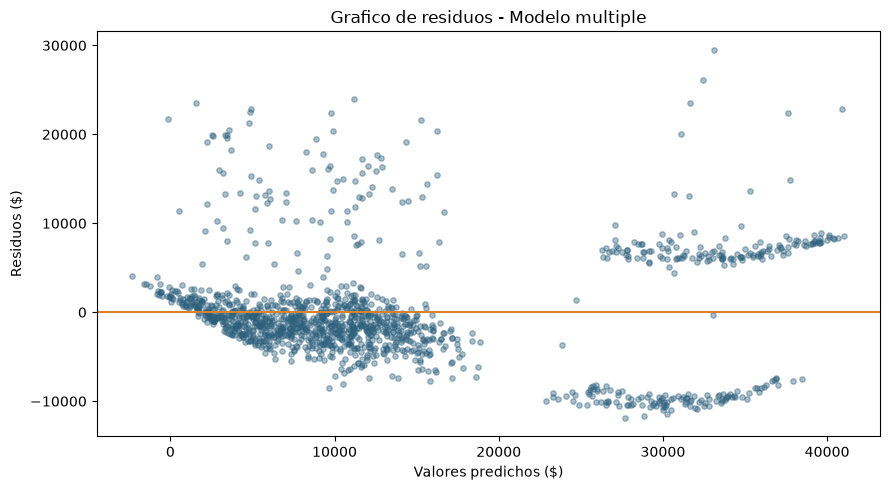

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(pred_multi, residuals_multi, alpha=0.4, s=15, color='#2C5F7C')
ax.axhline(0, color='#D9822B')
ax.set_xlabel('Valores predichos ($)')
ax.set_ylabel('Residuos ($)')
ax.set_title('Grafico de residuos - Modelo multiple')
plt.tight_layout()
plt.show()


📌 El modelo multiple alcanza R2 = 0.75, con `smoker_yes` como el predictor dominante (+$23.811). El grafico de residuos muestra un patron en abanico (heterocedasticidad), sugiriendo que una transformacion logaritmica de charges podria mejorar el ajuste en trabajos futuros.

## 🧠 Conclusion de negocio

Para ajustar primas de forma mas precisa, la aseguradora deberia priorizar el estatus de fumador como el factor de riesgo dominante en su modelo de tarificacion, muy por encima de la edad, el BMI o el numero de hijos.